# EDA — Kidney CT Classification Dataset
**Dataset:** CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone  
**Classes:** Normal, Cyst, Tumor, Stone  
**Framework:** TensorFlow / Python

---
This notebook covers:
1. Dataset mounting from Google Drive
2. Class distribution
3. Image dimension analysis
4. Pixel statistics, intensity, and contrast
5. Sample visualization by class
6. Intra-class variability analysis
7. Detection of corrupt or atypical images
8. Exact and near-duplicate verification
9. Patient-level stratified train/validation/test split
10. Class-weight calculation and modelling recommendations


## 0. Installation and configuration


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import cv2
from collections import defaultdict
import warnings
import hashlib
import re
warnings.filterwarnings('ignore')

# TensorFlow
import tensorflow as tf
print(f'TensorFlow version: {tf.__version__}')
print(f'GPU available: {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow version: 2.20.0
GPU available: False


## 1. Mount the dataset from Google Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Adjust this path to the dataset location in your Google Drive
DATASET_PATH = Path('/content/drive/MyDrive/BMET5933/Assignment 2/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone_unique')

CLASSES = ['Normal', 'Cyst', 'Tumor', 'Stone']

# Check folder structure
for cls in CLASSES:
  cls_path = DATASET_PATH / cls
  if cls_path.exists():
    count = sum(1 for p in cls_path.iterdir() if p.suffix.lower() in ['.jpg', '.jpeg', '.png'])
    print(f'{cls}: {count} images')
  else:
    print(f'{cls}: folder not found — check the path')

Mounted at /content/drive
Normal: 5002 images
Cyst: 3284 images
Tumor: 2283 images
Stone: 1360 images


## 2. Dataset inventory


In [ ]:
# Build a DataFrame with image-level metadata
records = []
VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png'}

for cls in CLASSES:
  cls_path = DATASET_PATH / cls
  if not cls_path.exists():
    continue

  for img_path in sorted(cls_path.iterdir()):
    if img_path.suffix.lower() in VALID_EXTENSIONS:
      records.append({
          'path': str(img_path),
          'class': cls,
          'filename': img_path.name,
          'extension': img_path.suffix.lower()
      })

df = pd.DataFrame(records)
print(f'Total images found: {len(df)}')
print('\nClass distribution:')
print(df['class'].value_counts())
print('\nFile extensions:')
print(df['extension'].value_counts())


Total images found: 11929

Class distribution:
class
Normal    5002
Cyst      3284
Tumor     2283
Stone     1360
Name: count, dtype: int64

File extensions:
extension
.jpg    11929
Name: count, dtype: int64


## 3. Class distribution — Class imbalance


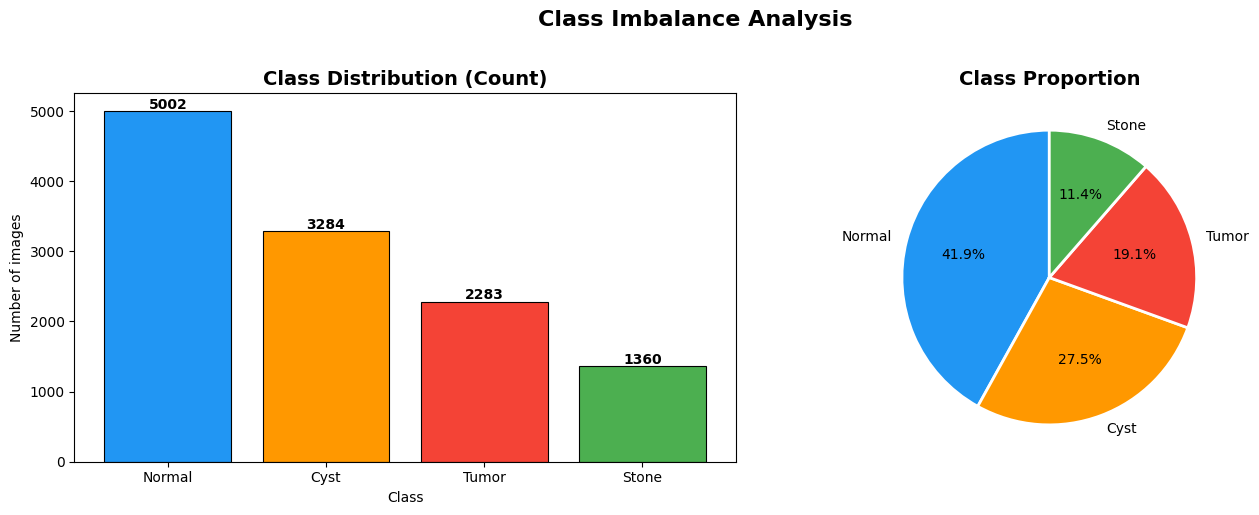


--- Imbalance Ratio ---
Normal: 5002 images | Ratio vs majority class: 1.00x
Cyst: 3284 images | Ratio vs majority class: 1.52x
Tumor: 2283 images | Ratio vs majority class: 2.19x
Stone: 1360 images | Ratio vs majority class: 3.68x


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_counts = df['class'].value_counts().reindex(CLASSES)
colors = ['#2196F3', '#FF9800', '#F44336', '#4CAF50']

# Bar chart
axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Class Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of images')
axes[0].set_xlabel('Class')
for i, (cls, val) in enumerate(class_counts.items()):
  axes[0].text(i, val + 30, str(val), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(
  class_counts.values,
  labels=class_counts.index,
  autopct='%1.1f%%',
  colors=colors,
  startangle=90,
  wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[1].set_title('Class Proportion', fontsize=14, fontweight='bold')

plt.suptitle('Class Imbalance Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Imbalance ratio
max_cls = class_counts.max()
print('\n--- Imbalance Ratio ---')
for cls, cnt in class_counts.items():
  ratio = max_cls / cnt
  print(f'{cls}: {cnt} images | Ratio vs majority class: {ratio:.2f}x')

## 4. Image dimension analysis


In [ ]:
# Sample 200 images per class for dimension analysis efficiency
dim_records = []
SAMPLE_N = 200

for cls in CLASSES:
  cls_df = df[df['class'] == cls].sample(min(SAMPLE_N, len(df[df['class'] == cls])), random_state=42)
  for _, row in cls_df.iterrows():
    try:
      with Image.open(row['path']) as img:
        w, h = img.size
        mode = img.mode
        dim_records.append({
          'class': cls,
          'width': w,
          'height': h,
          'aspect_ratio': w/h,
          'mode': mode,
          'path': row['path']
        })
    except Exception as e:
      print(f'Error reading {row["path"]}: {e}')

dim_df = pd.DataFrame(dim_records)

print('=== Dimension Statistics ===' )
print(dim_df.groupby('class')[['width', 'height']].describe().round(1))
print('\n=== Color Modes ===')
print(dim_df['mode'].value_counts())
print('\n=== Unique Dimensions ===')
unique_dims = dim_df.groupby(['width', 'height']).size().sort_values(ascending=False)
print(unique_dims.head(10))

=== Dimension Statistics ===
        width                                                   height         \
        count   mean    std    min    25%    50%    75%     max  count   mean   
class                                                                           
Cyst    200.0  662.8  192.4  512.0  512.0  512.0  781.0  1236.0  200.0  585.4   
Normal  200.0  616.0  152.4  512.0  512.0  512.0  759.5  1060.0  200.0  562.9   
Stone   200.0  647.2  226.7  512.0  512.0  512.0  746.0  1371.0  200.0  589.3   
Tumor   200.0  698.5  196.3  512.0  512.0  764.0  809.0  1271.0  200.0  609.8   

                                                   
          std    min    25%    50%    75%     max  
class                                              
Cyst    120.6  451.0  512.0  512.0  631.0  1001.0  
Normal   80.4  512.0  512.0  512.0  615.2   858.0  
Stone   146.9  512.0  512.0  512.0  602.8  1110.0  
Tumor   118.9  512.0  512.0  619.0  655.0  1029.0  

=== Color Modes ===
mode
RGB    800
Na

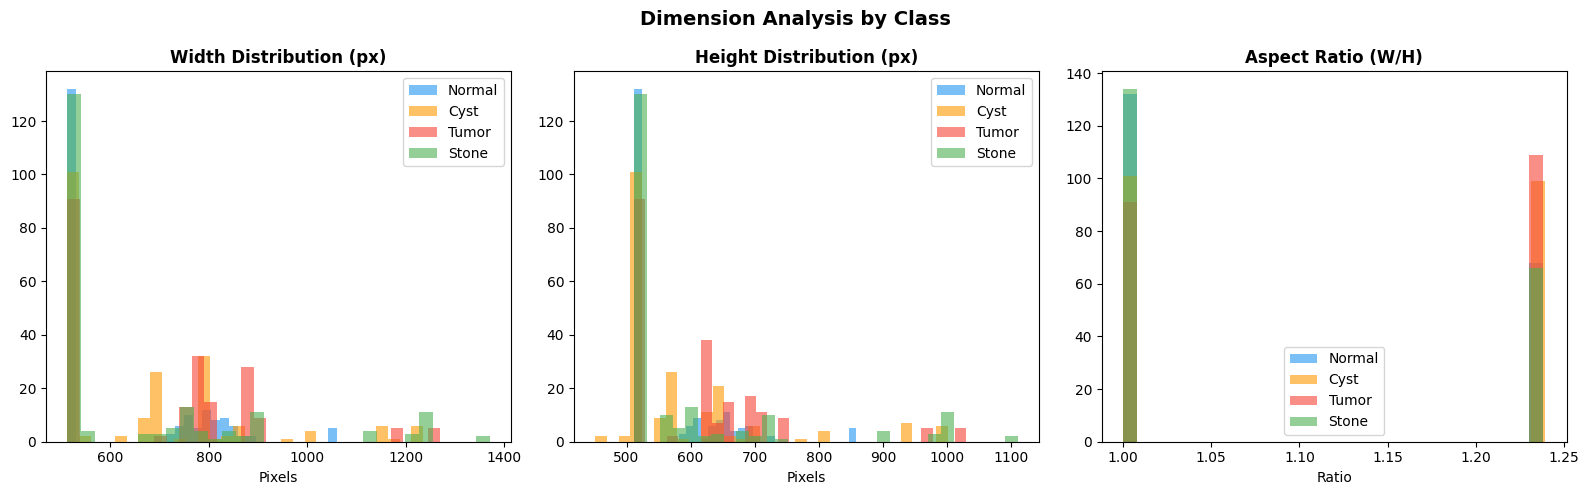

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, cls in enumerate(CLASSES):
  cls_data = dim_df[dim_df['class'] == cls]
  color = colors[i]

# Width distribution
for i, cls in enumerate(CLASSES):
  cls_data = dim_df[dim_df['class'] == cls]
  axes[0].hist(cls_data['width'], bins=30, alpha=0.6, label=cls, color=colors[i])
axes[0].set_title('Width Distribution (px)', fontweight='bold')
axes[0].set_xlabel('Pixels')
axes[0].legend()

# Height distribution
for i, cls in enumerate(CLASSES):
  cls_data = dim_df[dim_df['class'] == cls]
  axes[1].hist(cls_data['height'], bins=30, alpha=0.6, label=cls, color=colors[i])
axes[1].set_title('Height Distribution (px)', fontweight='bold')
axes[1].set_xlabel('Pixels')
axes[1].legend()

# Aspect ratio
for i, cls in enumerate(CLASSES):
  cls_data = dim_df[dim_df['class'] == cls]
  axes[2].hist(cls_data['aspect_ratio'], bins=30, alpha=0.6, label=cls, color=colors[i])
axes[2].set_title('Aspect Ratio (W/H)', fontweight='bold')
axes[2].set_xlabel('Ratio')
axes[2].legend()

plt.suptitle('Dimension Analysis by Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('dimension_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Pixel statistics analysis


In [ ]:
# Analyze pixel intensity by class
pixel_stats = []
PIXEL_SAMPLE = 100 # images per class
TARGET_SIZE = (224, 224)

for cls in CLASSES:
  cls_df = df[df['class'] == cls].sample(min(PIXEL_SAMPLE, len(df[df['class'] == cls])), random_state=42)
  for _, row in cls_df.iterrows():
    try:
      img = cv2.imread(row['path'], cv2.IMREAD_GRAYSCALE)
      if img is None:
        continue
      img = cv2.resize(img, TARGET_SIZE)
      pixel_stats.append({
        'class': cls,
        'mean': img.mean(),
        'std': img.std(),
        'min': img.min(),
        'max': img.max(),
        'contrast': img.max() - img.min(),
        'p25': np.percentile(img, 25),
        'p75': np.percentile(img, 75)
      })
    except Exception as e:
      pass

pixel_df = pd.DataFrame(pixel_stats)
print('=== Intensity Statistics by Class ===')
print(pixel_df.groupby('class')[['mean', 'std', 'contrast']].describe().round(2))

=== Intensity Statistics by Class ===
         mean                                                     std         \
        count   mean    std    min    25%    50%    75%    max  count   mean   
class                                                                          
Cyst    100.0  28.00   8.85  11.49  20.38  26.41  37.32  50.69  100.0  49.86   
Normal  100.0  42.46  14.29  18.27  32.25  39.83  48.48  76.19  100.0  63.20   
Stone   100.0  35.89  15.17  12.37  22.79  35.53  42.66  85.17  100.0  54.67   
Tumor   100.0  37.10  13.53  15.87  26.17  34.42  44.27  70.14  100.0  60.77   

        ...               contrast                                          \
        ...    75%    max    count   mean  std    min    25%    50%    75%   
class   ...                                                                  
Cyst    ...  58.69  75.79    100.0  255.0  0.0  255.0  255.0  255.0  255.0   
Normal  ...  69.46  85.86    100.0  255.0  0.0  255.0  255.0  255.0  255.0   
Stone   ...

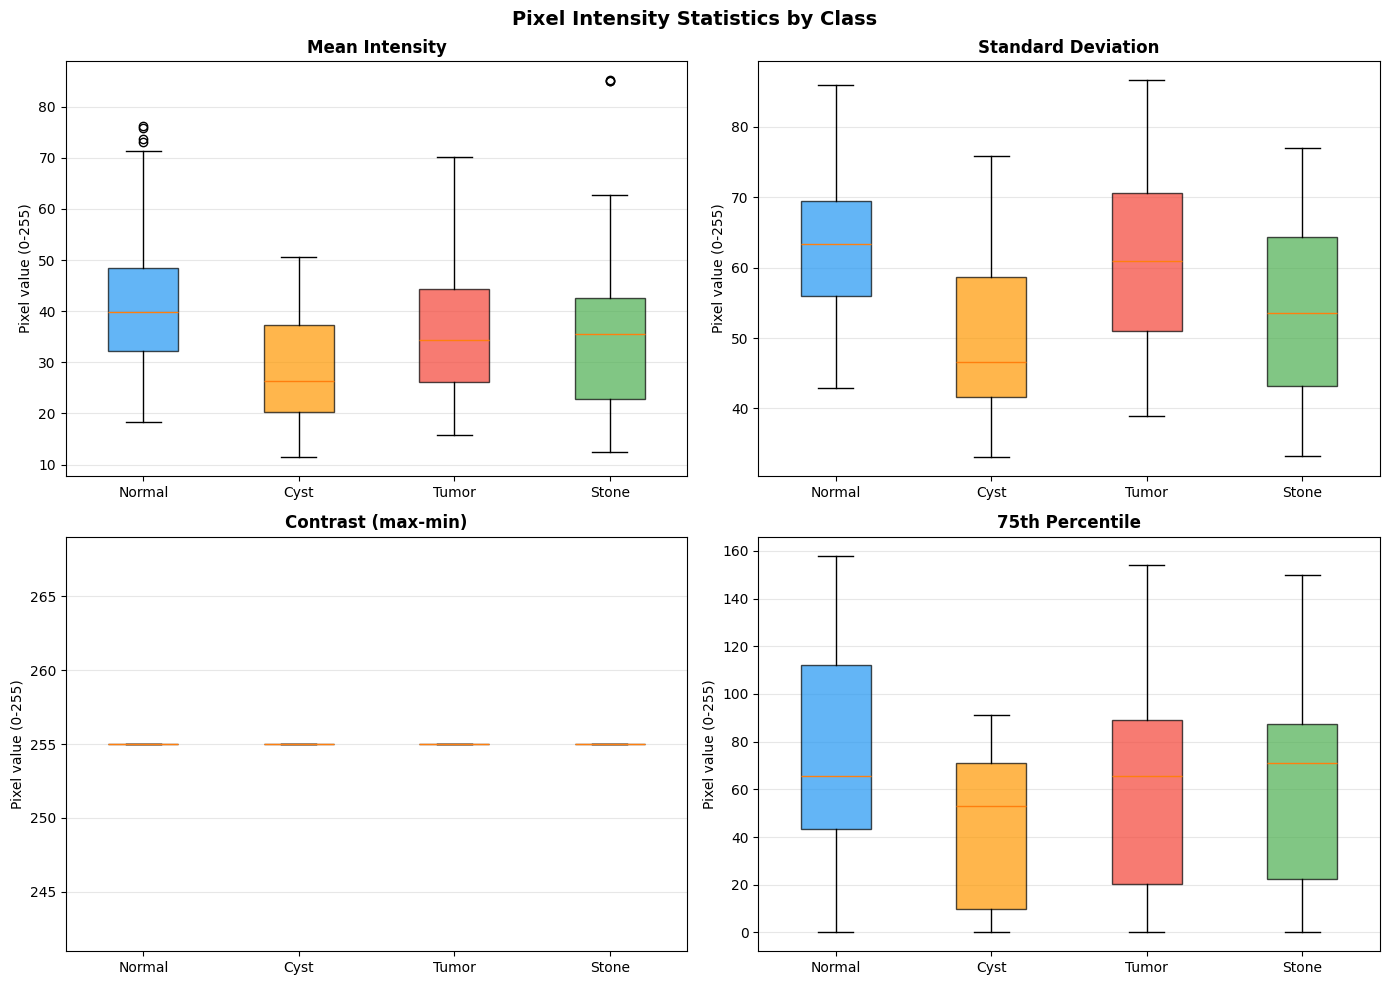

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = ['mean', 'std', 'contrast', 'p75']
titles = ['Mean Intensity', 'Standard Deviation', 'Contrast (max-min)', '75th Percentile']

for ax, metric, title in zip(axes.flatten(), metrics, titles):
  data_by_class = [pixel_df[pixel_df['class'] == cls][metric].values for cls in CLASSES]
  bp = ax.boxplot(data_by_class, labels=CLASSES, patch_artist=True)
  for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
  ax.set_title(title, fontweight='bold')
  ax.set_ylabel('Pixel value (0-255)')
  ax.grid(axis='y', alpha=0.3)

plt.suptitle('Pixel Intensity Statistics by Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('pixel_statistics.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Sample visualization by class


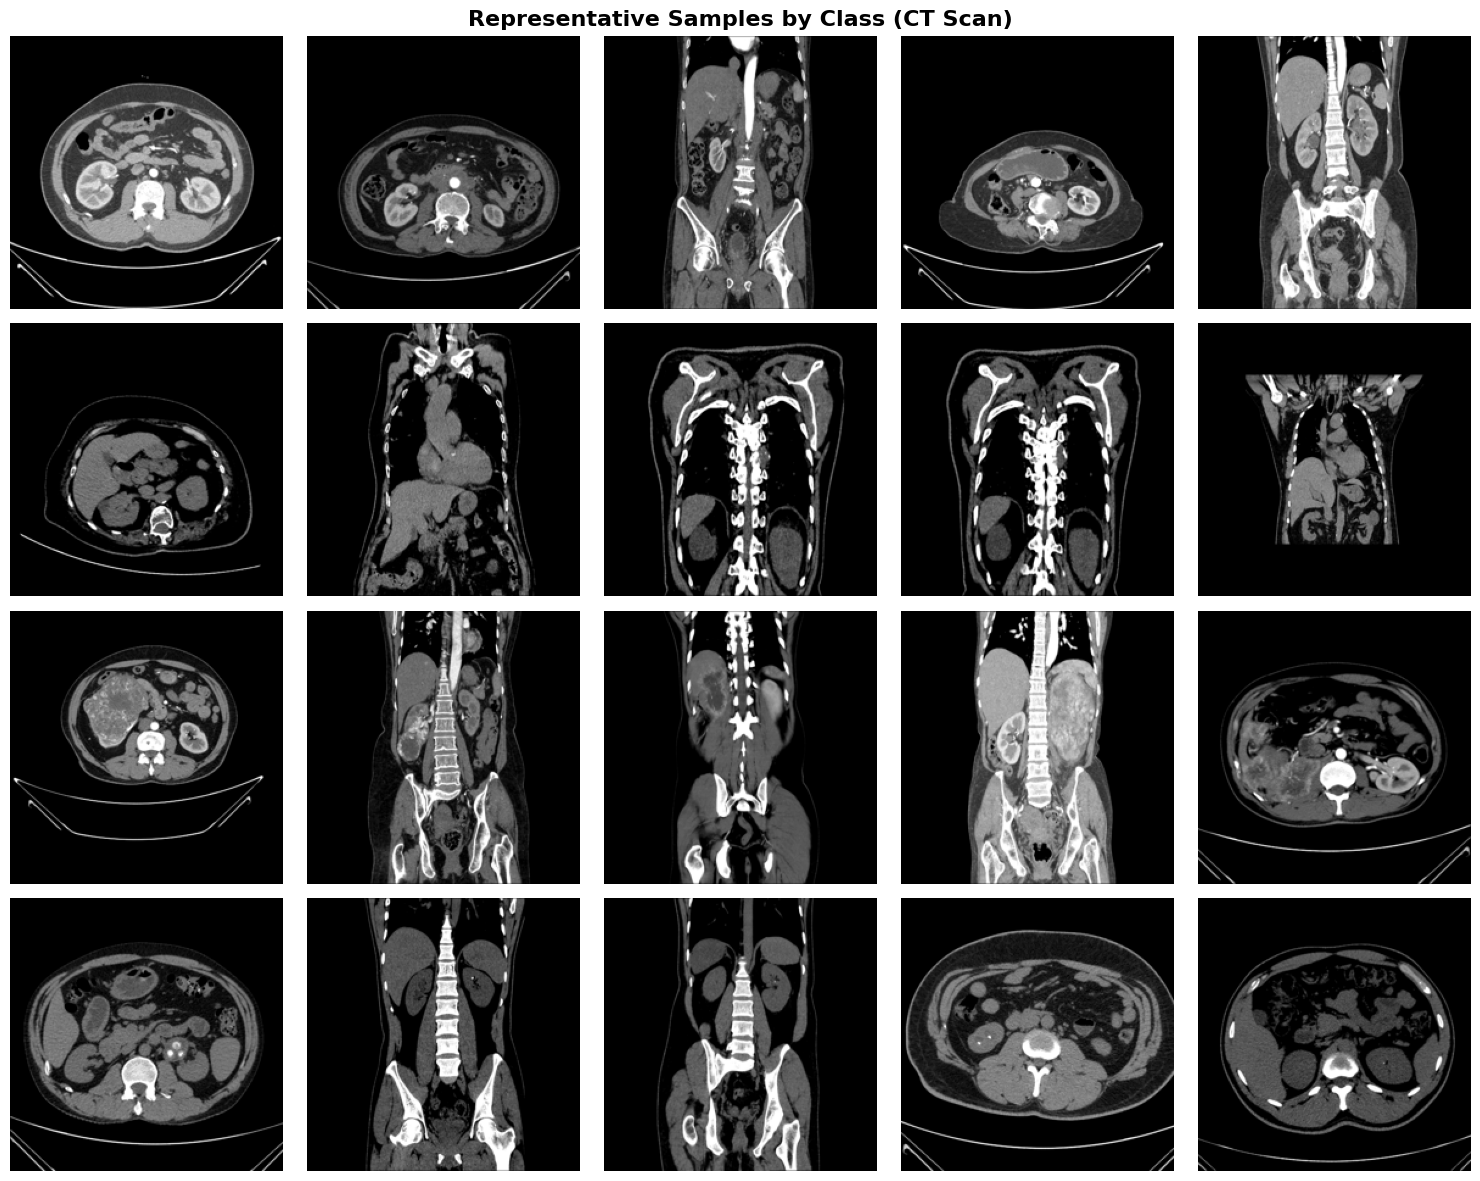

In [ ]:
# Display a grid of representative samples
N_SAMPLES = 5
fig, axes = plt.subplots(len(CLASSES), N_SAMPLES, figsize=(N_SAMPLES * 3, len(CLASSES) * 3))

for row_idx, cls in enumerate(CLASSES):
  cls_df = df[df['class'] == cls].sample(N_SAMPLES, random_state=42)
  for col_idx, (_, img_row) in enumerate(cls_df.iterrows()):
    img = Image.open(img_row['path']).convert('RGB')
    img = img.resize((224, 224))
    axes[row_idx, col_idx].imshow(img, cmap='gray')
    axes[row_idx, col_idx].axis('off')
    if col_idx == 0:
      axes[row_idx, col_idx].set_ylabel(cls, fontsize=13, fontweight='bold', rotation=90, labelpad=10)
      axes[row_idx, col_idx].yaxis.set_label_position('left')

plt.suptitle('Representative Samples by Class (CT Scan)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Average intensity histograms by class


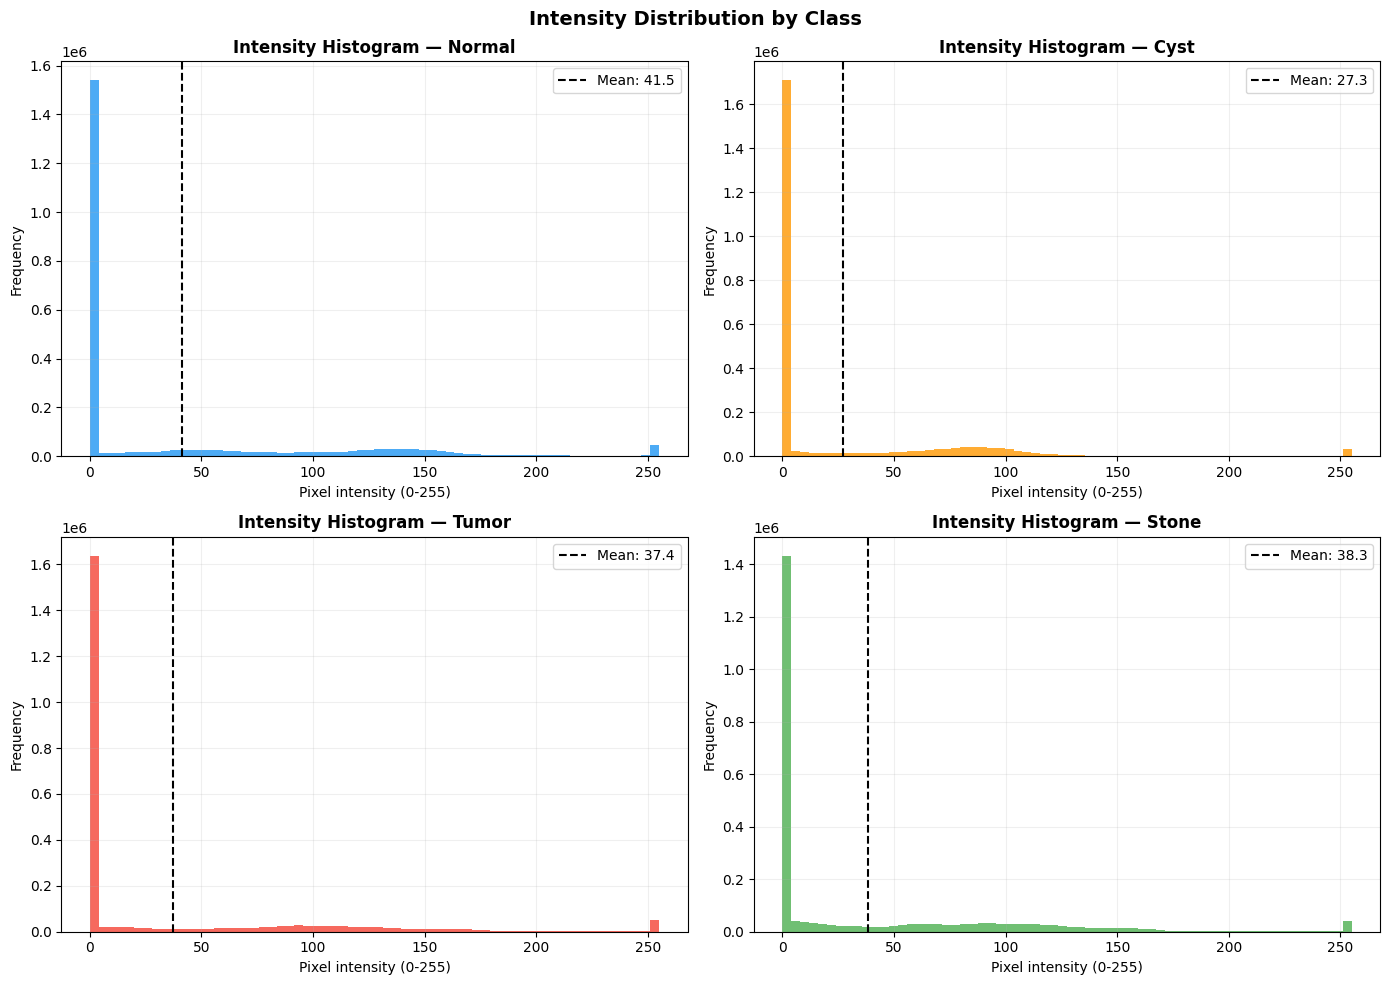

In [ ]:
# Average pixel intensity histogram
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, cls, color in zip(axes.flatten(), CLASSES, colors):
  cls_df = df[df['class'] == cls].sample(min(50, len(df[df['class'] == cls])), random_state=42)
  all_pixels = []
  for _, row in cls_df.iterrows():
    try:
      img = cv2.imread(row['path'], cv2.IMREAD_GRAYSCALE)
      if img is not None:
        img = cv2.resize(img, (224, 224))
        all_pixels.extend(img.flatten().tolist())
    except:
      pass
  ax.hist(all_pixels, bins=64, color=color, alpha=0.8, edgecolor='none')
  ax.set_title(f'Intensity Histogram — {cls}', fontweight='bold')
  ax.set_xlabel('Pixel intensity (0-255)')
  ax.set_ylabel('Frequency')
  ax.axvline(np.mean(all_pixels), color='black', linestyle='--', linewidth=1.5, label=f'Mean: {np.mean(all_pixels):.1f}')
  ax.legend()
  ax.grid(alpha=0.2)

plt.suptitle('Intensity Distribution by Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('intensity_histograms.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Detection of corrupt or problematic images


In [ ]:
corrupt = []
blank_threshold = 5.0 # very low std = nearly uniform image
blank_images = []

for cls in CLASSES:
  cls_df = df[df['class'] == cls]
  for _, row in cls_df.iterrows():
    try:
      img = Image.open(row['path'])
      img.verify() # detects corruption
    except (UnidentifiedImageError, Exception) as e:
      corrupt.append({'path': row['path'], 'class': cls, 'error': str(e)})
      continue

    # Detect blank or nearly uniform images
    try:
      img_arr = np.array(Image.open(row['path']).convert('L'))
      if img_arr.std() < blank_threshold:
        blank_images.append({'path': row['path'], 'class': cls, 'std': img_arr.std()})
    except:
      pass

print(f'Corrupt images found: {len(corrupt)}')
if corrupt:
  print(pd.DataFrame(corrupt))

print(f'\nNearly uniform images (possible blank images): {len(blank_images)}')
if blank_images:
  print(pd.DataFrame(blank_images).head(10))

Corrupt images found: 0

Nearly uniform images (possible blank images): 0


## 9. Duplicate and near-duplicate verification

This section checks for exact duplicates using file hashes and near-duplicates using a lightweight perceptual hash. In medical imaging, this step is important before splitting the dataset because duplicate or nearly identical images across train/validation/test can inflate performance estimates.


In [ ]:
# Exact and near-duplicate verification using file hash and perceptual hash
# No external dependency is required.

def compute_file_md5(path, chunk_size=8192):
  hasher = hashlib.md5()
  with open(path, 'rb') as f:
    for chunk in iter(lambda: f.read(chunk_size), b''):
      hasher.update(chunk)
  return hasher.hexdigest()


def average_hash(path, hash_size=8):
  """Return a simple perceptual hash for near-duplicate detection."""
  img = Image.open(path).convert('L').resize((hash_size, hash_size), Image.Resampling.LANCZOS)
  pixels = np.asarray(img, dtype=np.float32)
  return ''.join(['1' if p > pixels.mean() else '0' for p in pixels.flatten()])


def hamming_distance(hash_a, hash_b):
  return sum(ch1 != ch2 for ch1, ch2 in zip(hash_a, hash_b))

hash_records = []
for _, row in df.iterrows():
  try:
    hash_records.append({
        'path': row['path'],
        'filename': row['filename'],
        'class': row['class'],
        'md5': compute_file_md5(row['path']),
        'ahash': average_hash(row['path'])
    })
  except Exception as e:
    hash_records.append({
        'path': row['path'],
        'filename': row['filename'],
        'class': row['class'],
        'md5': None,
        'ahash': None,
        'hash_error': str(e)
    })

hash_df = pd.DataFrame(hash_records)

# Exact duplicates
exact_duplicate_groups = (
    hash_df.dropna(subset=['md5'])
           .groupby('md5')
           .filter(lambda x: len(x) > 1)
           .sort_values(['md5', 'class', 'filename'])
)

print(f'Exact duplicate images: {len(exact_duplicate_groups)} rows in duplicate groups')
if len(exact_duplicate_groups) > 0:
  display(exact_duplicate_groups[['md5', 'class', 'filename', 'path']].head(20))

# Near duplicates by identical perceptual hash
near_duplicate_groups = (
    hash_df.dropna(subset=['ahash'])
           .groupby('ahash')
           .filter(lambda x: len(x) > 1)
           .sort_values(['ahash', 'class', 'filename'])
)

print(f'Near-duplicate candidates with identical perceptual hash: {len(near_duplicate_groups)} rows')
if len(near_duplicate_groups) > 0:
  display(near_duplicate_groups[['ahash', 'class', 'filename', 'path']].head(30))

# Flag duplicate groups in the main DataFrame
md5_counts = hash_df['md5'].value_counts(dropna=True)
ahash_counts = hash_df['ahash'].value_counts(dropna=True)

df = df.merge(hash_df[['path', 'md5', 'ahash']], on='path', how='left')
df['is_exact_duplicate'] = df['md5'].map(md5_counts).fillna(0).astype(int) > 1
df['is_near_duplicate_candidate'] = df['ahash'].map(ahash_counts).fillna(0).astype(int) > 1

print('\nDuplicate summary by class:')
display(df.groupby('class')[['is_exact_duplicate', 'is_near_duplicate_candidate']].sum())

# Conservative dataset for splitting: keep the first image from each exact duplicate group.
# Near-duplicate candidates are flagged for review, but not automatically removed.
df_for_split = df.sort_values(['class', 'filename']).drop_duplicates(subset=['md5'], keep='first').reset_index(drop=True)
print(f'Images before exact-duplicate removal: {len(df)}')
print(f'Images after exact-duplicate removal: {len(df_for_split)}')


Exact duplicate images: 0 rows in duplicate groups
Near-duplicate candidates with identical perceptual hash: 11562 rows


,ahash,class,filename,path
790,0000000000000000000000000010111001111110011111...,Normal,Normal- (1778).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
791,0000000000000000000000000010111001111110011111...,Normal,Normal- (1779).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
793,0000000000000000000000000010111001111110011111...,Normal,Normal- (1780).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
794,0000000000000000000000000010111001111110011111...,Normal,Normal- (1781).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
795,0000000000000000000000000010111001111110011111...,Normal,Normal- (1782).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
7403,0000000000000000000000000011010001111110011111...,Cyst,Cyst- (3447).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
7404,0000000000000000000000000011010001111110011111...,Cyst,Cyst- (3448).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
7405,0000000000000000000000000011010001111110011111...,Cyst,Cyst- (3449).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
7485,0000000000000000000000000011011001111110001111...,Cyst,Cyst- (3528).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...
7486,0000000000000000000000000011011001111110001111...,Cyst,Cyst- (3529).jpg,/content/drive/MyDrive/BMET5933/Assignment 2/C...



Duplicate summary by class:


,is_exact_duplicate,is_near_duplicate_candidate
class,,
Cyst,0,3059
Normal,0,4942
Stone,0,1331
Tumor,0,2230


Images before exact-duplicate removal: 11929
Images after exact-duplicate removal: 11929


## 10. Intra-class variability analysis using PCA


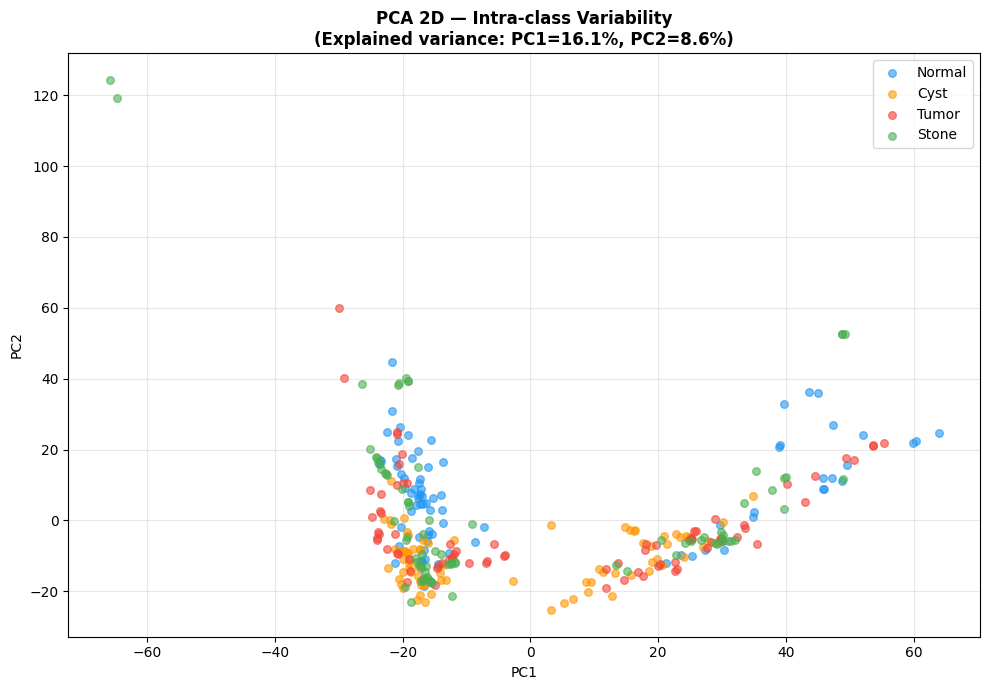


Explained variance total (2 PCs): 24.7%


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load sample for PCA
PCA_SAMPLE = 80 # per class
IMG_SIZE_PCA = (64, 64)

X_pca = []
y_pca = []

for cls_idx, cls in enumerate(CLASSES):
  cls_df = df[df['class'] == cls].sample(min(PCA_SAMPLE, len(df[df['class'] == cls])), random_state=42)
  for _, row in cls_df.iterrows():
    try:
      img = cv2.imread(row['path'], cv2.IMREAD_GRAYSCALE)
      img = cv2.resize(img, IMG_SIZE_PCA)
      X_pca.append(img.flatten())
      y_pca.append(cls_idx)
    except:
      pass

X_pca = np.array(X_pca, dtype=np.float32) / 255.0
y_pca = np.array(y_pca)

# PCA 2D
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
for cls_idx, cls in enumerate(CLASSES):
  mask = y_pca == cls_idx
  ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
        label=cls, alpha=0.6, s=30, color=colors[cls_idx])

ax.set_title(f'PCA 2D — Intra-class Variability\n(Explained variance: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%})',
       fontweight='bold')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pca_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nExplained variance total (2 PCs): {sum(pca.explained_variance_ratio_):.1%}')

## 11. Patient-level stratified train/validation/test split

The preferred split for medical image classification is patient-level splitting. This reduces leakage from repeated images or slices from the same subject. If the public dataset does not provide patient identifiers, the code attempts to infer them from filenames. If no reliable patient pattern is found, each image is treated as its own group and this limitation is explicitly reported.


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

# Configuration
DATASET_PATH = Path('/content/drive/MyDrive/BMET5933/Assignment 2/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone_unique')
CSV_PATH = '/content/drive/MyDrive/BMET5933/Assignment 2/kidneyData.csv'
OUT_PATH = '/content/drive/MyDrive/BMET5933/Assignment 2/dataset_split.csv'

CLASSES = ['Normal', 'Cyst', 'Tumor', 'Stone']

# Mapping: class name to the exact subfolder name in Google Drive
FOLDER_MAP = {
    'Normal': 'Normal',
    'Cyst': 'Cyst',
    'Tumor': 'Tumor',
    'Stone': 'Stone',
}

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
RANDOM_SEED = 42

# Safety check: ratios must sum to 1.0
assert abs((TRAIN_RATIO + VAL_RATIO + TEST_RATIO) - 1.0) < 1e-8, \
    "TRAIN_RATIO, VAL_RATIO and TEST_RATIO must sum to 1.0"

# 1. Load CSV file
df_raw = pd.read_csv(CSV_PATH, index_col=0)

# 2. Reconstruct real image paths
def rebuild_path(row):
    folder = FOLDER_MAP[row['Class']]
    filename = row['image_id'] + '.jpg'
    return str(DATASET_PATH / folder / filename)

df_raw['path'] = df_raw.apply(rebuild_path, axis=1)
df_raw['filename'] = df_raw['image_id'] + '.jpg'
df_raw['class'] = df_raw['Class']

df = df_raw[['image_id', 'filename', 'path', 'class', 'target']].reset_index(drop=True)

print(f'Total images in CSV: {len(df)}')
print('\nOriginal class distribution:')
print(df['class'].value_counts().reindex(CLASSES))

# 3. Important methodological note
print('\nMethodological note:')
print('The dataset does not provide explicit patient identifiers.')
print('Therefore, a confirmed patient-level split cannot be performed.')
print('This code performs a stratified image-level split by class.')

# 4. Stratified image-level split
# First split: train vs temporary set
train_df, temp_df = train_test_split(
    df,
    train_size=TRAIN_RATIO,
    random_state=RANDOM_SEED,
    shuffle=True,
    stratify=df['class']
)

# Second split: validation vs test
# Since temp = 30%, validation and test are each 15%.
relative_val_ratio = VAL_RATIO / (VAL_RATIO + TEST_RATIO)

val_df, test_df = train_test_split(
    temp_df,
    train_size=relative_val_ratio,
    random_state=RANDOM_SEED,
    shuffle=True,
    stratify=temp_df['class']
)

# 5. Add split labels
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df['split'] = 'train'
val_df['split'] = 'val'
test_df['split'] = 'test'

split_df = pd.concat([train_df, val_df, test_df], axis=0).reset_index(drop=True)

# 6. Verify split distribution
print('\n=== Image-level distribution by split ===')
split_counts = (
    split_df
    .groupby(['split', 'class'])
    .size()
    .unstack(fill_value=0)
    .reindex(index=['train', 'val', 'test'])
    .reindex(columns=CLASSES)
)

print(split_counts)

print('\n=== Percentage of each class assigned to each split ===')
class_totals = df['class'].value_counts().reindex(CLASSES)

split_percentages = split_counts.copy().astype(float)

for cls in CLASSES:
    split_percentages[cls] = split_percentages[cls] / class_totals[cls]

print((split_percentages * 100).round(2))

# 7. Verify global split proportions
print('\n=== Total images per split ===')
split_total_counts = split_df['split'].value_counts().reindex(['train', 'val', 'test'])
print(split_total_counts)

print('\n=== Global split percentages ===')
print((split_total_counts / len(split_df) * 100).round(2))

# 8. Check for missing or duplicated rows after splitting
print('\n=== Split integrity checks ===')

original_ids = set(df.index)
split_ids = set(split_df.index)

print(f'Total original images: {len(df)}')
print(f'Total split images:    {len(split_df)}')

duplicated_image_ids = split_df['image_id'].duplicated().sum()
print(f'Duplicated image_id rows in split_df: {duplicated_image_ids}')

missing_paths = split_df['path'].isna().sum()
print(f'Missing image paths: {missing_paths}')

# 9. Save split CSV file
split_df.to_csv(OUT_PATH, index=False)

print(f'\nSplit file saved to: {OUT_PATH}')

Total images in CSV: 12446

Original class distribution:
class
Normal    5077
Cyst      3709
Tumor     2283
Stone     1377
... [30 lines of log output omitted for readability] ...
train    70.0
val      15.0
test     15.0
Name: count, dtype: float64

=== Split integrity checks ===
Total original images: 12446
Total split images:    12446
Duplicated image_id rows in split_df: 0
Missing image paths: 0

Split file saved to: /content/drive/MyDrive/BMET5933/Assignment 2/dataset_split.csv


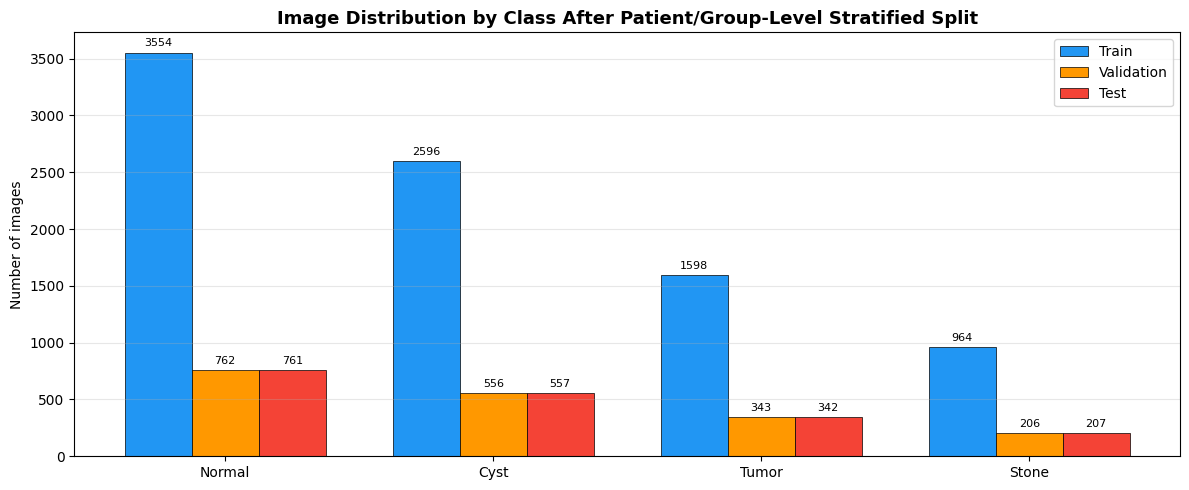

In [ ]:
# Visualize the patient/group-aware split
fig, ax = plt.subplots(figsize=(12, 5))

split_counts = split_df.groupby(['class', 'split']).size().unstack(fill_value=0)
split_counts = split_counts.reindex(CLASSES)

for split_name in ['train', 'val', 'test']:
  if split_name not in split_counts.columns:
    split_counts[split_name] = 0

x = np.arange(len(CLASSES))
width = 0.25

bars1 = ax.bar(x - width, split_counts['train'], width, label='Train', color='#2196F3', edgecolor='black', lw=0.5)
bars2 = ax.bar(x, split_counts['val'], width, label='Validation', color='#FF9800', edgecolor='black', lw=0.5)
bars3 = ax.bar(x + width, split_counts['test'], width, label='Test', color='#F44336', edgecolor='black', lw=0.5)

ax.set_title('Image Distribution by Class After Patient/Group-Level Stratified Split', fontweight='bold', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel('Number of images')
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar_group in [bars1, bars2, bars3]:
  for bar in bar_group:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + max(1, split_counts.values.max() * 0.01),
            str(int(height)), ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('split_distribution_patient_level.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Class weight analysis for imbalance handling


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

train_df = split_df[split_df['split'] == 'train']

# Map classes to integer labels
class_to_idx = {cls: idx for idx, cls in enumerate(CLASSES)}
y_train = train_df['class'].map(class_to_idx).values

class_weights = compute_class_weight(
  class_weight='balanced',
  classes=np.unique(y_train),
  y=y_train
)

class_weight_dict = {i: w for i, w in enumerate(class_weights)}
print('=== Class Weights (balanced) ===')
for cls, w in zip(CLASSES, class_weights):
  print(f' {cls}: {w:.4f}')

print('\nThese weights can be used in model.fit(class_weight=class_weight_dict)')

=== Class Weights (balanced) ===
 Normal: 0.6128
 Cyst: 0.8390
 Tumor: 1.3630
 Stone: 2.2593

These weights can be used in model.fit(class_weight=class_weight_dict)


## 13. EDA executive summary


In [ ]:
print('=' * 60)
print('EDA EXECUTIVE SUMMARY')
print('=' * 60)

total = len(df)
print(f'\nTOTAL DATASET: {total} images')
for cls in CLASSES:
  cnt = len(df[df['class'] == cls])
  print(f'  {cls}: {cnt} ({cnt/total*100:.1f}%)')

print('\nCLASS IMBALANCE:')
majority_class = df['class'].value_counts().idxmax()
minority_class = df['class'].value_counts().idxmin()
imbalance_ratio = df['class'].value_counts().max() / df['class'].value_counts().min()
print(f'  Majority class ({majority_class}) vs minority class ({minority_class}): {imbalance_ratio:.1f}x')
print('  - Use class weights and report macro-F1, balanced accuracy, sensitivity/specificity, and ROC-AUC or PR-AUC when appropriate.')

print('\nIMAGE QUALITY AND DUPLICATES:')
print(f'  Corrupt images found: {len(corrupt) if "corrupt" in globals() else "not evaluated"}')
print(f'  Nearly uniform images: {len(blank_images) if "blank_images" in globals() else "not evaluated"}')
if 'df' in globals() and 'is_exact_duplicate' in df.columns:
  print(f'  Exact duplicate rows: {int(df["is_exact_duplicate"].sum())}')
  print(f'  Near-duplicate candidate rows: {int(df["is_near_duplicate_candidate"].sum())}')

print('\nDIMENSIONS:')
print('  - Resize to 224x224 for pretrained CNN/ViT compatibility.')
print('  - Most images are grayscale; convert to RGB by replicating the channel if using ImageNet-pretrained models.')

print('\nSPLIT STRATEGY:')
print('  - Preferred strategy: patient/group-level split with class stratification.')
print('  - Exact duplicates are removed before splitting.')
print('  - If no reliable patient ID exists, the notebook reports this limitation explicitly.')
print('  - Seed=42 for reproducibility.')

print('\nMODELLING DECISIONS:')
print('  1. Four-class classification: Normal vs Cyst vs Tumor vs Stone.')
print('  2. Preprocessing: resize 224x224 and normalize pixel values.')
print('  3. Augmentation should be applied only after the split and only to the training set.')
print('  4. Include a CNN baseline before claiming ViT superiority.')
print('  5. If ViT is used, report patch-size experiments and explainability maps with quantitative sanity checks.')
print('=' * 60)


EDA EXECUTIVE SUMMARY

TOTAL DATASET: 12446 images
  Normal: 5077 (40.8%)
  Cyst: 3709 (29.8%)
  Tumor: 2283 (18.3%)
  Stone: 1377 (11.1%)

CLASS IMBALANCE:
  Majority class (Normal) vs minority class (Stone): 3.7x
  - Use class weights and report macro-F1, balanced accuracy, sensitivity/specificity, and ROC-AUC or PR-AUC when appropriate.

IMAGE QUALITY AND DUPLICATES:
  Corrupt images found: 0
  Nearly uniform images: 0

DIMENSIONS:
  - Resize to 224x224 for pretrained CNN/ViT compatibility.
  - Most images are grayscale; convert to RGB by replicating the channel if using ImageNet-pretrained models.

SPLIT STRATEGY:
  - Preferred strategy: patient/group-level split with class stratification.
  - Exact duplicates are removed before splitting.
  - If no reliable patient ID exists, the notebook reports this limitation explicitly.
  - Seed=42 for reproducibility.

MODELLING DECISIONS:
  1. Four-class classification: Normal vs Cyst vs Tumor vs Stone.
  2. Preprocessing: resize 224x224 and

In [ ]:
#@title Function to read Train/Val/Test
import pandas as pd
from pathlib import Path

def load_split_datasets(
    split_csv_path='/content/drive/MyDrive/BMET5933/Assignment 2/dataset_split.csv',
    check_paths=True
):
    """
    Load train, validation and test DataFrames from the generated split CSV.

    Parameters
    ----------
    split_csv_path : str or Path
        Path to the CSV file generated after the stratified split.

    check_paths : bool
        If True, checks whether image paths exist on disk.

    Returns
    -------
    df_train : pandas.DataFrame
        DataFrame containing training samples.

    df_val : pandas.DataFrame
        DataFrame containing validation samples.

    df_test : pandas.DataFrame
        DataFrame containing test samples.
    """

    split_csv_path = Path(split_csv_path)

    if not split_csv_path.exists():
        raise FileNotFoundError(f'Split CSV file not found: {split_csv_path}')

    df = pd.read_csv(split_csv_path)

    required_columns = {'image_id', 'filename', 'path', 'class', 'target', 'split'}
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(f'Missing required columns in split CSV: {missing_columns}')

    valid_splits = {'train', 'val', 'test'}
    found_splits = set(df['split'].unique())

    if not found_splits.issubset(valid_splits):
        raise ValueError(f'Unexpected split labels found: {found_splits - valid_splits}')

    df_train = df[df['split'] == 'train'].reset_index(drop=True)
    df_val = df[df['split'] == 'val'].reset_index(drop=True)
    df_test = df[df['split'] == 'test'].reset_index(drop=True)

    if check_paths:
        for name, subset in {
            'train': df_train,
            'val': df_val,
            'test': df_test
        }.items():
            missing_paths = subset['path'].apply(lambda p: not Path(p).exists()).sum()
            print(f'Missing image paths in {name}: {missing_paths}')

    print('Datasets loaded successfully.')
    print(f'Train samples:      {len(df_train)}')
    print(f'Validation samples: {len(df_val)}')
    print(f'Test samples:       {len(df_test)}')

    print('\nClass distribution - Train:')
    print(df_train['class'].value_counts())

    print('\nClass distribution - Validation:')
    print(df_val['class'].value_counts())

    print('\nClass distribution - Test:')
    print(df_test['class'].value_counts())

    return df_train, df_val, df_test

df_train, df_val, df_test = load_split_datasets(
    split_csv_path='/content/drive/MyDrive/BMET5933/Assignment 2/dataset_split.csv'
)

Missing image paths in train: 348
Missing image paths in val: 93
Missing image paths in test: 76
Datasets loaded successfully.
Train samples:      8712
Validation samples: 1867
Test samples:       1867

Class distribution - Train:
class
Normal    3554
Cyst      2596
Tumor     1598
Stone      964
Name: count, dtype: int64

Class distribution - Validation:
class
Normal    762
Cyst      556
Tumor     343
Stone     206
Name: count, dtype: int64

Class distribution - Test:
class
Normal    761
Cyst      557
Tumor     342
Stone     207
Name: count, dtype: int64


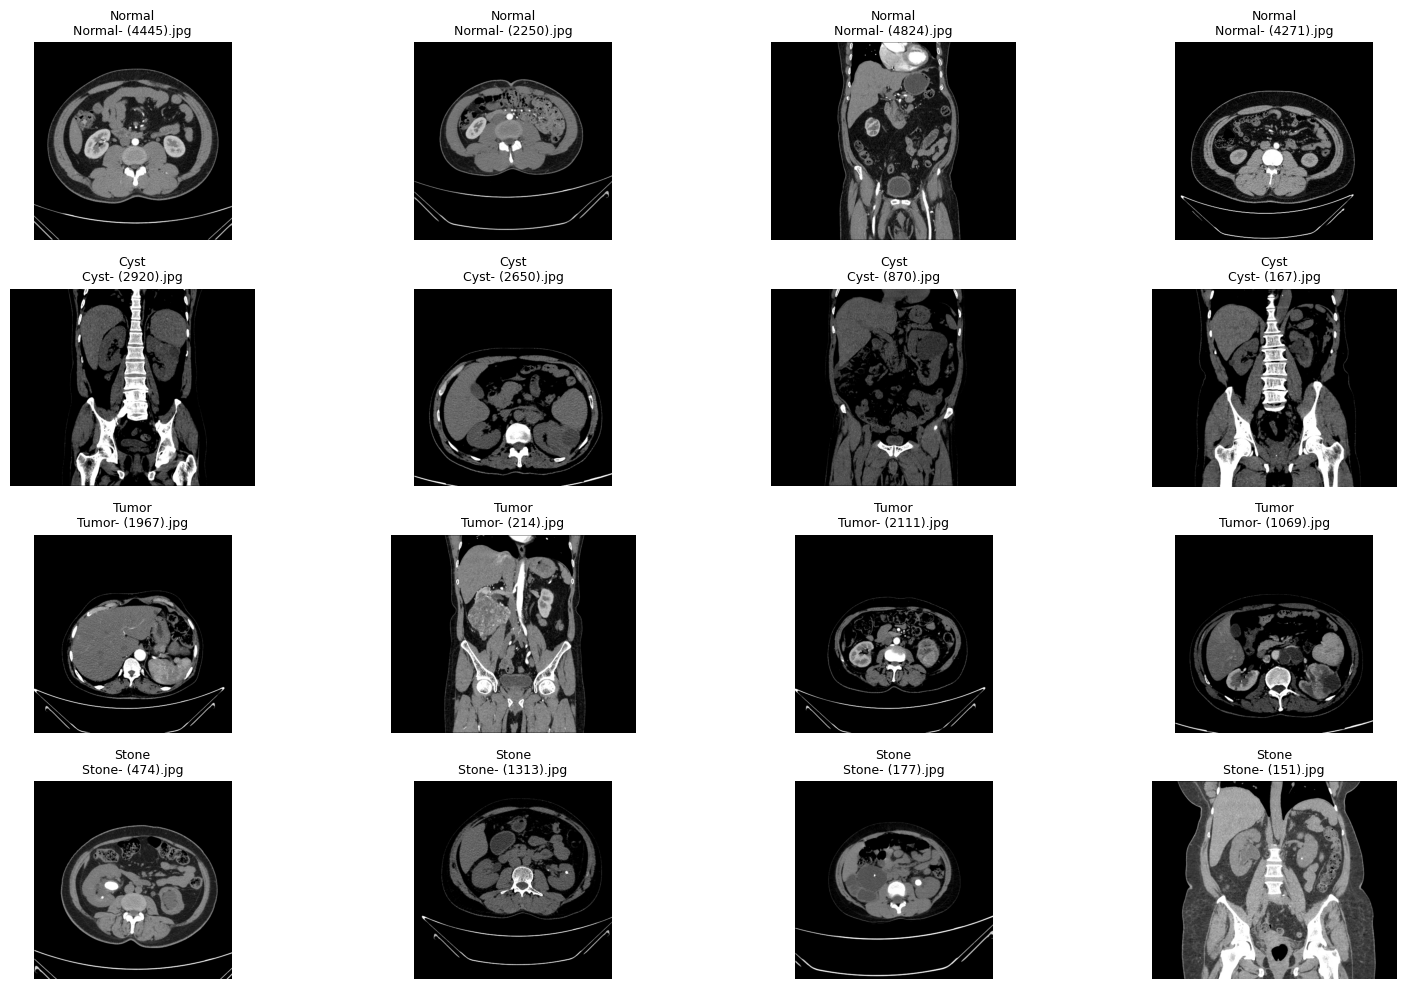

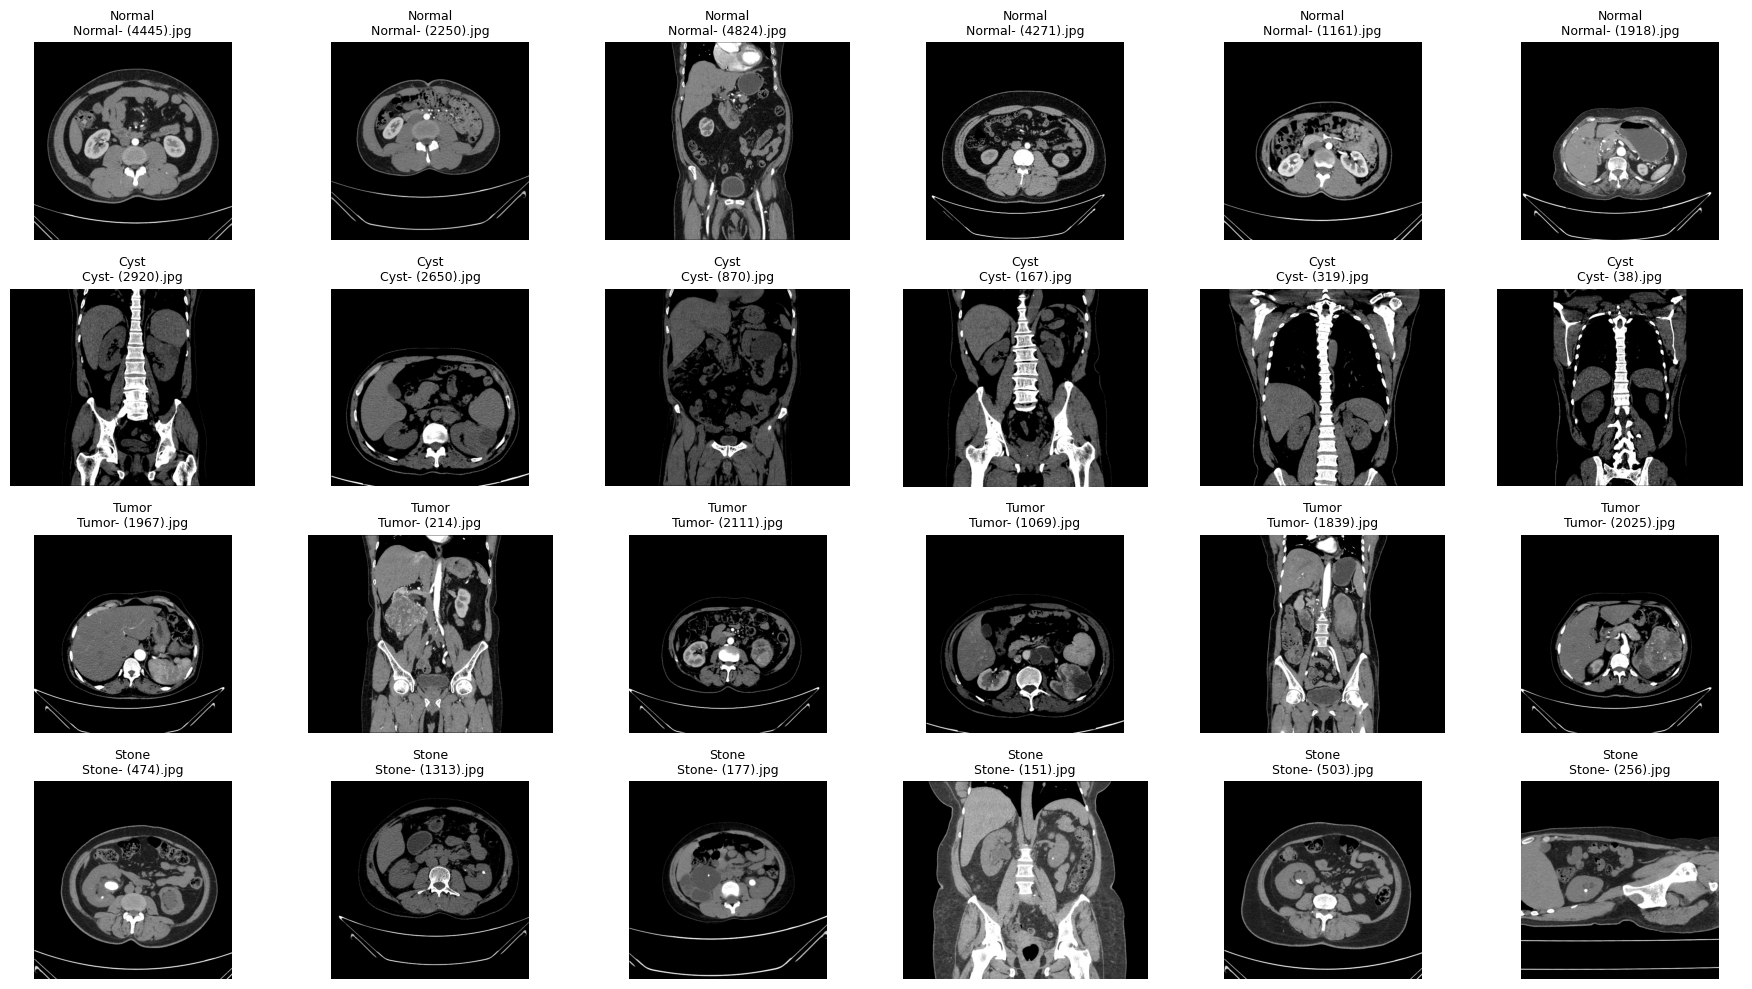

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from pathlib import Path

def show_samples_from_df(
    df,
    class_col='class',
    path_col='path',
    classes=None,
    samples_per_class=4,
    figsize=(14, 10),
    random_seed=42
):
    """
    Display sample images from a DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing image paths and class labels.

    class_col : str
        Name of the column containing class labels.

    path_col : str
        Name of the column containing image paths.

    classes : list or None
        List of classes to display. If None, classes are inferred from the DataFrame.

    samples_per_class : int
        Number of images to display per class.

    figsize : tuple
        Figure size.

    random_seed : int
        Random seed for reproducibility.
    """

    if classes is None:
        classes = sorted(df[class_col].unique())

    n_classes = len(classes)
    n_cols = samples_per_class
    n_rows = n_classes

    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)

    if n_rows == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, cls in enumerate(classes):
        class_df = df[df[class_col] == cls]

        if len(class_df) == 0:
            print(f'No samples found for class: {cls}')
            continue

        n_samples = min(samples_per_class, len(class_df))

        sampled_df = class_df.sample(
            n=n_samples,
            random_state=random_seed
        )

        for col_idx in range(n_cols):
            ax = axes[row_idx, col_idx]
            ax.axis('off')

            if col_idx >= n_samples:
                continue

            img_path = Path(sampled_df.iloc[col_idx][path_col])

            try:
                img = Image.open(img_path).convert('L')
                ax.imshow(img, cmap='gray')
                ax.set_title(f'{cls}\n{img_path.name}', fontsize=9)
            except Exception as e:
                ax.set_title(f'{cls}\nError loading image', fontsize=9)
                print(f'Error loading {img_path}: {e}')

    plt.tight_layout()
    plt.show()

CLASSES = ['Normal', 'Cyst', 'Tumor', 'Stone']

show_samples_from_df(
    df_train,
    classes=CLASSES,
    samples_per_class=4,
    figsize=(16, 10)
)

show_samples_from_df(
    df_train,
    classes=CLASSES,
    samples_per_class=6,
    figsize=(18, 10)
)

In [ ]:
##@title Preprocessing

import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image_from_path(path, label, img_size=IMG_SIZE, repeat_channels=True):
    """
    Load and preprocess a CT JPG image.

    Steps:
    - Read image file.
    - Decode as grayscale.
    - Resize to a fixed spatial size.
    - Normalize pixel values to [0, 1].
    - Optionally repeat grayscale channel to 3 channels.
    """

    image = tf.io.read_file(path)

    image = tf.image.decode_jpeg(
        image,
        channels=1
    )

    image = tf.image.resize(
        image,
        [img_size, img_size],
        method='bilinear'
    )

    image = tf.cast(image, tf.float32) / 255.0

    if repeat_channels:
        image = tf.repeat(image, repeats=3, axis=-1)

    return image, label


def make_tf_dataset(
    df,
    path_col='path',
    label_col='target',
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    augment=False,
    repeat_channels=True
):
    """
    Create a TensorFlow dataset from a DataFrame containing image paths and labels.
    """

    paths = df[path_col].astype(str).values
    labels = df[label_col].astype(int).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        lambda path, label: load_image_from_path(
            path,
            label,
            img_size=img_size,
            repeat_channels=repeat_channels
        ),
        num_parallel_calls=AUTOTUNE
    )

    if augment:
        augmentation = tf.keras.Sequential([
            tf.keras.layers.RandomRotation(0.03),
            tf.keras.layers.RandomZoom(0.10),
            tf.keras.layers.RandomTranslation(0.05, 0.05),
            tf.keras.layers.RandomContrast(0.10),
        ])

        ds = ds.map(
            lambda image, label: (augmentation(image, training=True), label),
            num_parallel_calls=AUTOTUNE
        )

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_tf_dataset(
    df_train,
    shuffle=True,
    augment=True,
    repeat_channels=True
)

val_ds = make_tf_dataset(
    df_val,
    shuffle=False,
    augment=False,
    repeat_channels=True
)

test_ds = make_tf_dataset(
    df_test,
    shuffle=False,
    augment=False,
    repeat_channels=True
)